In [1]:
import pickle
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from torch.autograd import Function
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import mutual_info_classif
from imblearn.over_sampling import SMOTE
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import (
    classification_report, balanced_accuracy_score,
    roc_auc_score, f1_score, confusion_matrix,
    matthews_corrcoef, cohen_kappa_score
)
import seaborn as sns

In [2]:
with open('/kaggle/input/notebooks/matildeteixeira/wesad-preprocess/processed_data.pkl', 'rb') as f:
    data = pickle.load(f)

df           = data['df']
X            = data['X']
y            = data['y']
groups       = data['groups']
feature_cols = data['feature_cols']

le = LabelEncoder()
domain_labels = le.fit_transform(groups) 

print(df.shape)
print(y.value_counts())

(27543, 139)
label
0    17577
1     9966
Name: count, dtype: int64


In [3]:
class GRL(Function):
    @staticmethod
    def forward(ctx, x, lam):
        ctx.lam = lam
        return x  # forward: passa sem alterar

    @staticmethod
    def backward(ctx, grad):
        return grad.neg() * ctx.lam, None  # backward: inverte o gradiente

In [4]:
class FeatureExtractor(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.rede = nn.Sequential(
            nn.Linear(n_features, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU()
        )
    def forward(self, x):
        return self.rede(x)

In [5]:
class StressClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.rede = nn.Sequential(
            nn.Linear(64,  32),   
            nn.ReLU(),                  
            nn.Linear(32, 2),    
        )

    def forward(self, x):
        return self.rede(x)

In [6]:
class DomainDiscriminator(nn.Module):
    def __init__(self, n_subjects):       
        super().__init__()
        self.rede = nn.Sequential(
            nn.Linear(64, 32),  
            nn.ReLU(),
            nn.Linear(32, n_subjects),  
        )

    def forward(self, x, lam):
        x = GRL.apply(x, lam)     # GRL inverte o gradiente
        return self.rede(x)

In [7]:
class DANN(nn.Module):
    def __init__(self, n_features, n_subjects):
        super().__init__()
        self.extractor   = FeatureExtractor(n_features)        
        self.stress_cls  = StressClassifier()            
        self.domain_dis  = DomainDiscriminator(n_subjects)         

    def forward(self, x, lam):
        z           = self.extractor(x)               
        stress_out  = self.stress_cls (z)               
        domain_out  = self.domain_dis (z, lam)          
        return stress_out, domain_out      

In [8]:
logo     = LeaveOneGroupOut()
all_true = []
all_pred = []
fold_f1s = []
ig_scores_por_fold = []

for train_idx, test_idx in logo.split(X, y, groups):

    X_train = X.iloc[train_idx];  X_test = X.iloc[test_idx]
    y_train = y.iloc[train_idx];  y_test = y.iloc[test_idx]
    d_train = domain_labels[train_idx]  # labels de sujeito do treino

    # 1. scaler + imputer
    scaler  = StandardScaler()
    imputer = SimpleImputer(strategy='mean')
    X_train_proc = imputer.fit_transform(scaler.fit_transform(X_train))
    X_test_proc  = imputer.transform(scaler.transform(X_test))

    # 2. IG feature selection
    ig_scores = mutual_info_classif(X_train_proc, y_train, random_state=42)
    ig_scores_por_fold.append(ig_scores)
    top_k_idx = np.argsort(ig_scores)[::-1][:20]
    X_train_sel = X_train_proc[:, top_k_idx]
    X_test_sel  = X_test_proc[:, top_k_idx]

    # 3. SMOTE — junta features + domain labels para resample consistente
    smote = SMOTE(random_state=42)
    X_temp, y_train_res = smote.fit_resample(
        np.column_stack([X_train_sel, d_train]), y_train
    )
    X_train_sm = X_temp[:, :-1]
    d_train_sm = X_temp[:, -1].astype(int)

    le_fold    = LabelEncoder()
    d_train_sm = le_fold.fit_transform(d_train_sm)
    n_subjects = len(le_fold.classes_) 

    # 4. converter para tensores
    Xt = torch.FloatTensor(X_train_sm)
    yt = torch.LongTensor(y_train_res.values)
    dt = torch.LongTensor(d_train_sm)

    # 5. criar modelo
    n_features = X_train_sm.shape[1]
    model      = DANN(n_features=n_features, n_subjects=n_subjects)
    optimizer  = torch.optim.Adam(model.parameters(), lr=1e-3)
    loss_fn_stress = nn.CrossEntropyLoss(weight=torch.FloatTensor([1.0, 1.76]))
    loss_fn_domain = nn.CrossEntropyLoss() 

    # 6. treino
    model.train()
    for epoch in range(250):
        lam = 0.5 * (2 / (1 + np.exp(-10 * epoch / 250)) - 1) # λ máx = 0.5

        stress_out, domain_out = model(Xt, lam)

        loss_stress = loss_fn_stress(stress_out, yt)
        loss_domain = loss_fn_domain(domain_out, dt)
        loss_total  = loss_stress + 0.1 * loss_domain

        optimizer.zero_grad()
        loss_total.backward()
        # torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)  # gradient clipping
        optimizer.step()

    # 7. avaliação
    model.eval()
    with torch.no_grad():
        stress_out, _ = model(torch.FloatTensor(X_test_sel), lam=0)
        y_pred        = stress_out.argmax(dim=1).numpy()

    all_true.extend(y_test)
    all_pred.extend(y_pred)
    fold_f1s.append(f1_score(y_test, y_pred, average='macro', zero_division=0))

Estatísticas FINAIS - DANN + IG + SMOTE
              precision    recall  f1-score   support

    baseline       0.87      0.88      0.87     17577
      stress       0.78      0.77      0.77      9966

    accuracy                           0.84     27543
   macro avg       0.82      0.82      0.82     27543
weighted avg       0.84      0.84      0.84     27543

Balanced Accuracy:        0.822
Macro F1 médio por fold:  0.800
Desvio Padrão F1 (LOSO):  0.176
Matthews Corr. Coef.:     0.647
Cohen's Kappa:            0.647

F1 por fold:
  Sujeito 01: 0.893
  Sujeito 02: 0.584
  Sujeito 03: 0.692
  Sujeito 04: 0.956
  Sujeito 05: 0.831
  Sujeito 06: 0.999
  Sujeito 07: 0.926
  Sujeito 08: 0.606
  Sujeito 09: 0.645
  Sujeito 10: 0.852
  Sujeito 11: 0.995
  Sujeito 12: 0.953
  Sujeito 13: 0.400
  Sujeito 14: 0.953
  Sujeito 15: 0.709


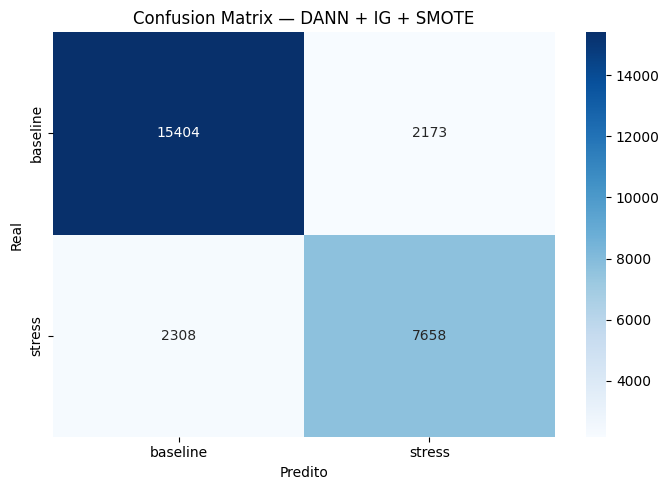

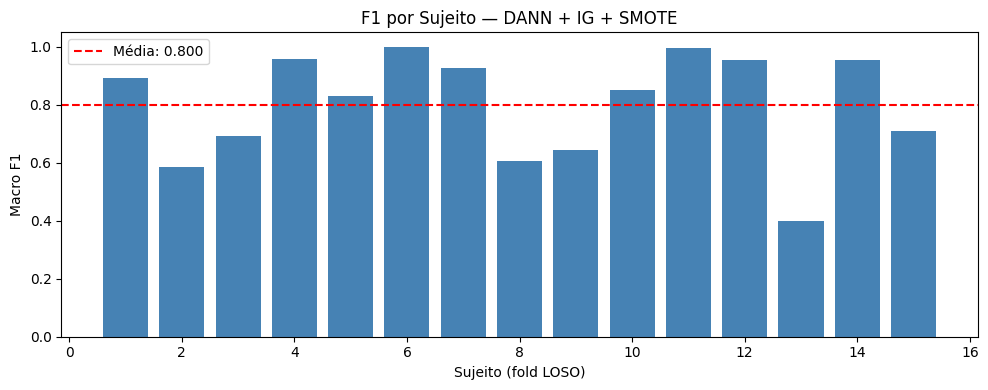

In [9]:
# converter para arrays
all_true = np.array(all_true)
all_pred = np.array(all_pred)

print("=" * 50)
print("Estatísticas FINAIS - DANN + IG + SMOTE")
print("=" * 50)

print(classification_report(all_true, all_pred,
                             target_names=['baseline', 'stress'],
                             zero_division=0))

print(f"Balanced Accuracy:        {balanced_accuracy_score(all_true, all_pred):.3f}")
print(f"Macro F1 médio por fold:  {np.mean(fold_f1s):.3f}")
print(f"Desvio Padrão F1 (LOSO):  {np.std(fold_f1s):.3f}")
print(f"Matthews Corr. Coef.:     {matthews_corrcoef(all_true, all_pred):.3f}")
print(f"Cohen's Kappa:            {cohen_kappa_score(all_true, all_pred):.3f}")

# F1 por fold (para ver estabilidade entre sujeitos)
print(f"\nF1 por fold:")
for i, f1 in enumerate(fold_f1s):
    print(f"  Sujeito {i+1:02d}: {f1:.3f}")

# matriz de confusão
plt.figure(figsize=(7, 5))
sns.heatmap(confusion_matrix(all_true, all_pred),
            annot=True, fmt='d', cmap='Blues',
            xticklabels=['baseline', 'stress'],
            yticklabels=['baseline', 'stress'])
plt.title('Confusion Matrix — DANN + IG + SMOTE')
plt.ylabel('Real'); plt.xlabel('Predito')
plt.tight_layout()
plt.show()

# F1 por fold em gráfico — mostra estabilidade inter-sujeito
plt.figure(figsize=(10, 4))
plt.bar(range(1, len(fold_f1s)+1), fold_f1s, color='steelblue')
plt.axhline(np.mean(fold_f1s), color='red', linestyle='--',
            label=f'Média: {np.mean(fold_f1s):.3f}')
plt.xlabel('Sujeito (fold LOSO)')
plt.ylabel('Macro F1')
plt.title('F1 por Sujeito — DANN + IG + SMOTE')
plt.legend()
plt.tight_layout()
plt.show()

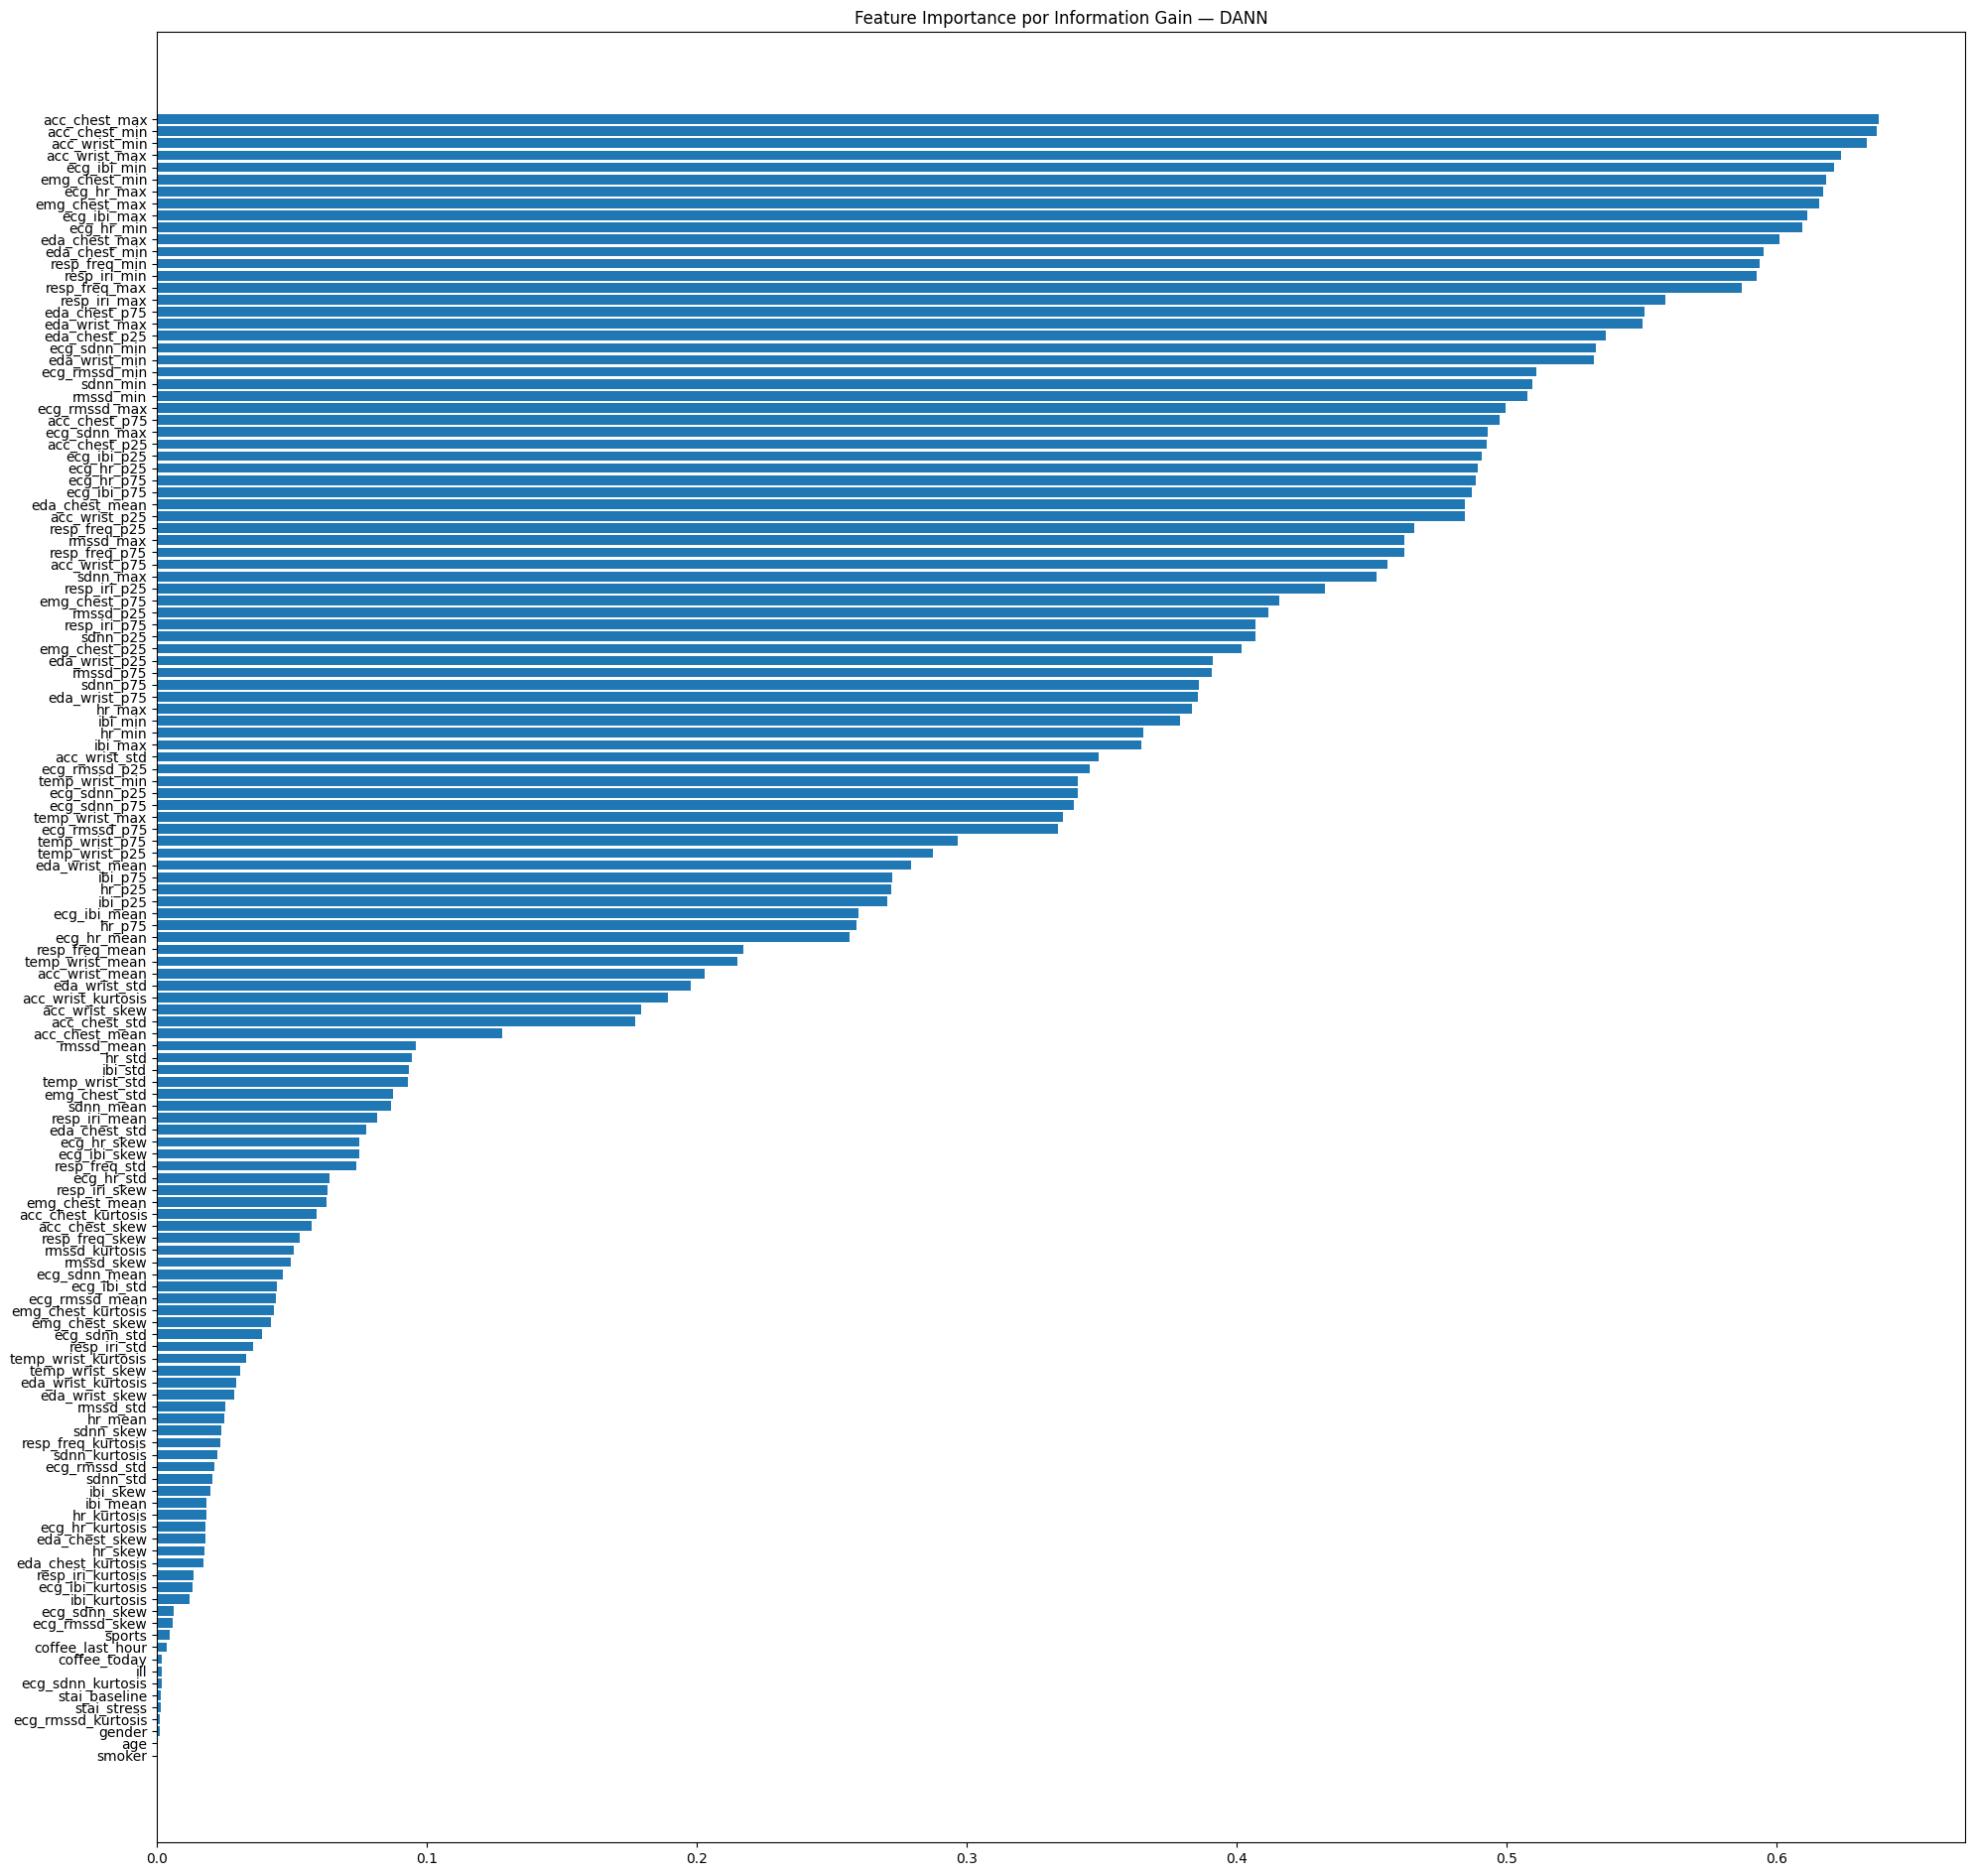

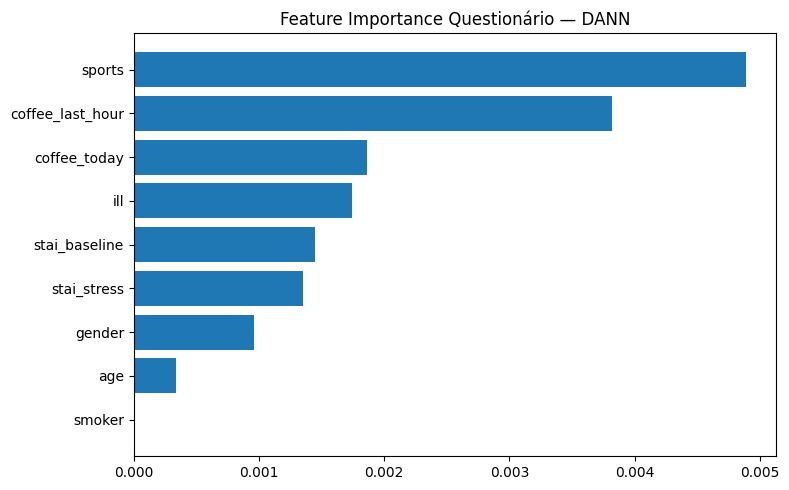

In [10]:
# média dos scores IG entre todos os folds
ig_medio = np.mean(ig_scores_por_fold, axis=0)
indices  = np.argsort(ig_medio)

# todas as features
plt.figure(figsize=(20, 19))
plt.barh(np.array(feature_cols)[indices], ig_medio[indices])
plt.title("Feature Importance por Information Gain — DANN")
plt.tight_layout()
plt.show()

# só features de questionário
quest_cols = ['age', 'gender', 'coffee_today', 'coffee_last_hour',
              'sports', 'smoker', 'ill', 'stai_baseline', 'stai_stress']

quest_indices      = [list(feature_cols).index(c) for c in quest_cols]
quest_importances  = ig_medio[quest_indices]
indices_q          = np.argsort(quest_importances)

plt.figure(figsize=(8, 5))
plt.barh(np.array(quest_cols)[indices_q], quest_importances[indices_q])
plt.title("Feature Importance Questionário — DANN")
plt.tight_layout()
plt.show()